
=== Structural Dependency Chapters ===
    ProductCode                   ProductDescription  Deficit_Years  \
5             6  LIVE TREES AND OTHER PLANTS; BULBS,             12   
18           19  PREPARATIONS OF CEREALS, FLOUR, STA             12   
71           72                       IRON AND STEEL             12   
19           20  PREPARATIONS OF VEGETABLES, FRUIT,              12   
10           11  PRODUCTS OF THE MILLING INDUSTRY; M             11   
46           47  PULP OF WOOD OR OF OTHER FIBROUS CE             11   
73           74          COPPER AND ARTICLES THEREOF             10   
30           31                          FERTILISERS             10   
76           78            LEAD AND ARTICLES THEREOF             10   
14           15  ANIMAL OR VEGETABLE FATS AND OILS A              8   

    Mean_Net_Trade  Avg_Reexport_Ratio  
5    -6.510202e+04           14.525671  
18   -4.633752e+05           27.476388  
71   -2.214604e+06           20.206205  
19   -1.898488

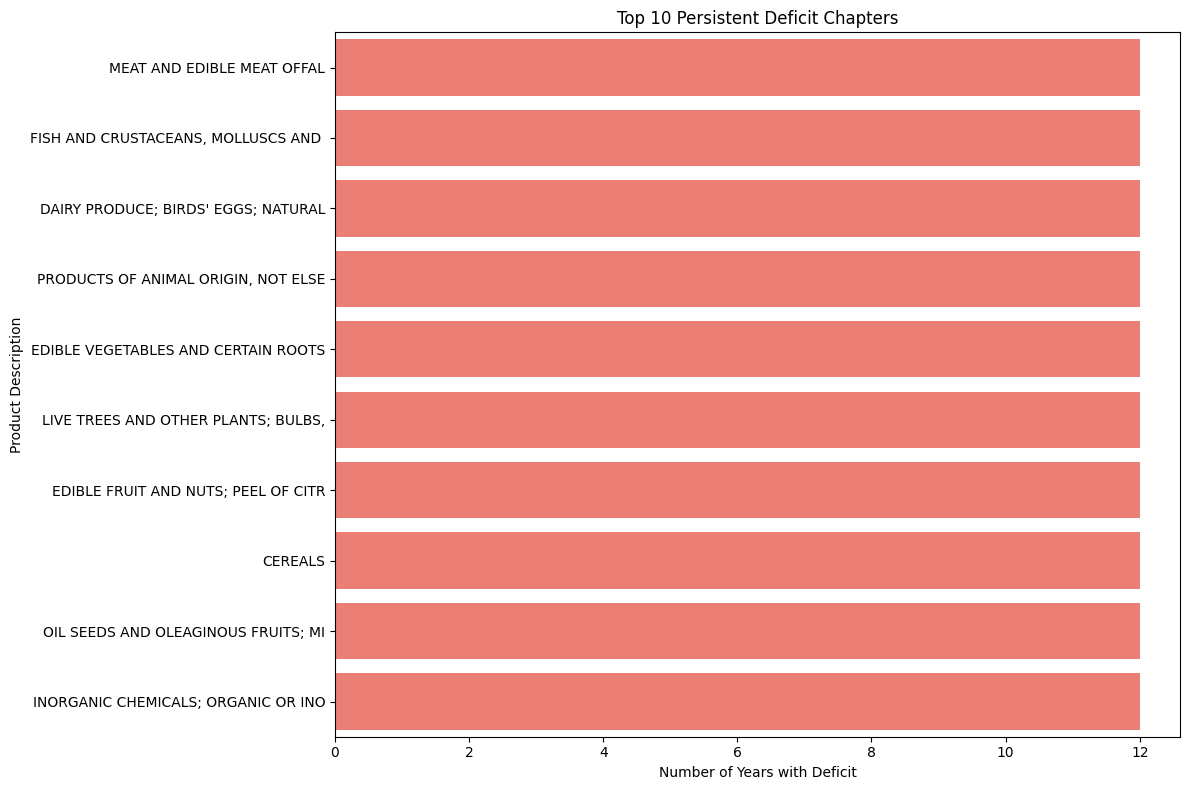

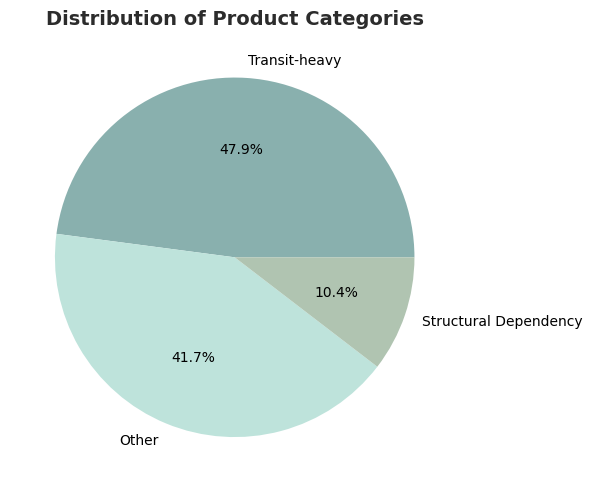

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- LOAD DATA ---
df = pd.read_csv('/content/drive/MyDrive/Datasets/DataJobID-2982251_2982251_UAEtrade.csv', encoding='latin1')

# Ensure TradeValue column exists
if 'TradeValue in 1000 USD' in df.columns:
    df.rename(columns={'TradeValue in 1000 USD': 'TradeValueK'}, inplace=True)
else:
    df['TradeValueK'] = df['TradeValueK']  # If already exists

# --- STANDARDIZE TradeFlowName ---
df['TradeFlowName'] = df['TradeFlowName'].str.strip().map(lambda x: {
    'Export':'Export', 'Exports':'Export',
    'Re-Export':'Re-Export', 'Re-Exports':'Re-Export', 'Reexport':'Re-Export', 'Reexports':'Re-Export',
    'Import':'Import', 'Imports':'Import', 'Import (CIF)':'Import', 'Imports (CIF)':'Import'
}.get(x, x))

# --- AGGREGATE DATA ---
agg = df.groupby(['ProductCode','Year','ProductDescription','TradeFlowName'], as_index=False)['TradeValueK'].sum()
pivot = agg.pivot(index=['ProductCode','Year','ProductDescription'], columns='TradeFlowName', values='TradeValueK').fillna(0).reset_index()

for c in ['Export','Re-Export','Import']:
    if c not in pivot.columns: pivot[c] = 0

# --- CALCULATE METRICS ---
pivot['Total_Exports']  = pivot['Export'] + pivot['Re-Export']
pivot['Net_Trade']      = pivot['Total_Exports'] - pivot['Import']
pivot['Reexport_Ratio'] = np.where(pivot['Total_Exports']>0, 100 * pivot['Re-Export']/pivot['Total_Exports'], 0)

# --- SUMMARY BY PRODUCT ---
summary = pivot.groupby(['ProductCode','ProductDescription'], as_index=False).agg(
    Total_Years=('Year','count'),
    Deficit_Years=('Net_Trade', lambda x: (x<0).sum()),
    Mean_Net_Trade=('Net_Trade','mean'),
    Avg_Reexport_Ratio=('Reexport_Ratio','mean')
)

# --- CATEGORIZE PRODUCTS ---
summary['Flag_Persistent'] = summary['Deficit_Years'] >= 8
summary['Category'] = summary.apply(
    lambda r: 'Structural Dependency' if r['Flag_Persistent'] and r['Avg_Reexport_Ratio'] <= 30
              else ('Transit-heavy' if r['Flag_Persistent'] and r['Avg_Reexport_Ratio'] > 60 else 'Other'), axis=1
)

# --- FINAL TABLES ---
top_deficit = summary.sort_values(by='Deficit_Years', ascending=False).head(15)
structural_df = summary[summary['Category']=='Structural Dependency'].sort_values(by='Deficit_Years', ascending=False)
transit_df    = summary[summary['Category']=='Transit-heavy'].sort_values(by='Deficit_Years', ascending=False)


# --- DISPLAY TABLES ---
top_deficit[['ProductCode','ProductDescription','Deficit_Years','Mean_Net_Trade','Avg_Reexport_Ratio']]

print("\n=== Structural Dependency Chapters ===")
print(structural_df[['ProductCode','ProductDescription','Deficit_Years','Mean_Net_Trade','Avg_Reexport_Ratio']])

print("\n=== Transit-Heavy Chapters ===")
print(transit_df[['ProductCode','ProductDescription','Deficit_Years','Mean_Net_Trade','Avg_Reexport_Ratio']])

# --- BAR CHART: TOP 10 PERSISTENT DEFICIT CHAPTERS ---
top10 = top_deficit.head(10)
plt.figure(figsize=(12,8))
sns.barplot(
    x='Deficit_Years', y='ProductDescription',
    data=top10, color='#FF6F61'
)
plt.title('Top 10 Persistent Deficit Chapters')
plt.xlabel('Number of Years with Deficit')
plt.ylabel('Product Description')
plt.tight_layout()
plt.show()

# --- PIE CHART: CATEGORY DISTRIBUTION ---
cat_counts = summary['Category'].value_counts()

# Custom palette from your suggestion
custom_colors = ['#89B0AE', '#BEE3DB', '#B0C4B1', '#C6AC8F', '#EDDDD4']

plt.figure(figsize=(6,6))
plt.pie(
    cat_counts,
    labels=cat_counts.index,
    autopct='%1.1f%%',
    colors=custom_colors[:len(cat_counts)]  # match number of categories
)
plt.title('Distribution of Product Categories', fontsize=14, fontweight='bold', color='#2C2C2C')
plt.tight_layout()
plt.show()



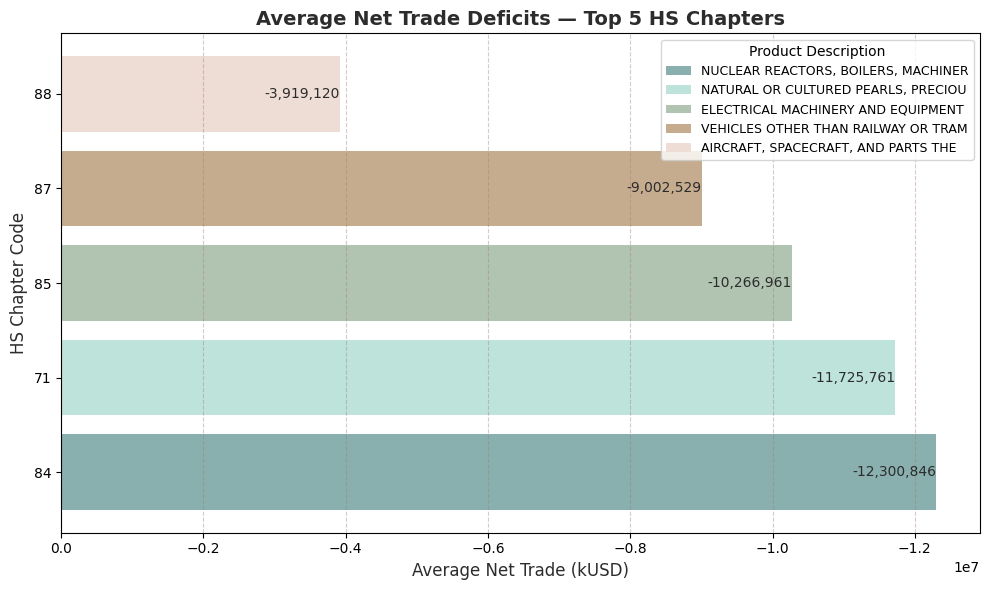

In [20]:
import matplotlib.pyplot as plt

# --- Select top 5 chapters by average net trade deficit (most negative Mean_Net_Trade) ---
top5_deficits = summary.sort_values(by='Mean_Net_Trade').head(5)

# --- Sort in ascending order (most negative at top) ---
top5_deficits = top5_deficits.sort_values(by='Mean_Net_Trade')

# --- Custom palette for each product (updated last color to #EDDDD4) ---
custom_colors = ['#89B0AE', '#BEE3DB', '#B0C4B1', '#C6AC8F', '#EDDDD4']

# --- Plot horizontal bar chart ---
plt.figure(figsize=(10,6))
bars = plt.barh(top5_deficits['ProductCode'].astype(str),
                top5_deficits['Mean_Net_Trade'],
                color=custom_colors)

# --- Annotate deficit values ---
for bar, val in zip(bars, top5_deficits['Mean_Net_Trade']):
    plt.text(val - 5000, bar.get_y() + bar.get_height()/2,
             f"{val:,.0f}", va='center', ha='right', fontsize=10, color='#2C2C2C')

# --- Styling ---
plt.title("Average Net Trade Deficits — Top 5 HS Chapters",
          fontsize=14, fontweight='bold', color='#2C2C2C')
plt.xlabel("Average Net Trade (kUSD)", fontsize=12, color='#2C2C2C')
plt.ylabel("HS Chapter Code", fontsize=12, color='#2C2C2C')
plt.grid(axis='x', linestyle='--', alpha=0.4, color='#A17C6B')  # earthy brown gridlines
plt.gca().invert_xaxis()  # flip chart so bars extend from right to left

# --- Legend with descriptions ---
plt.legend(bars, top5_deficits['ProductDescription'],
           title="Product Description", fontsize=9)

plt.tight_layout()
plt.show()


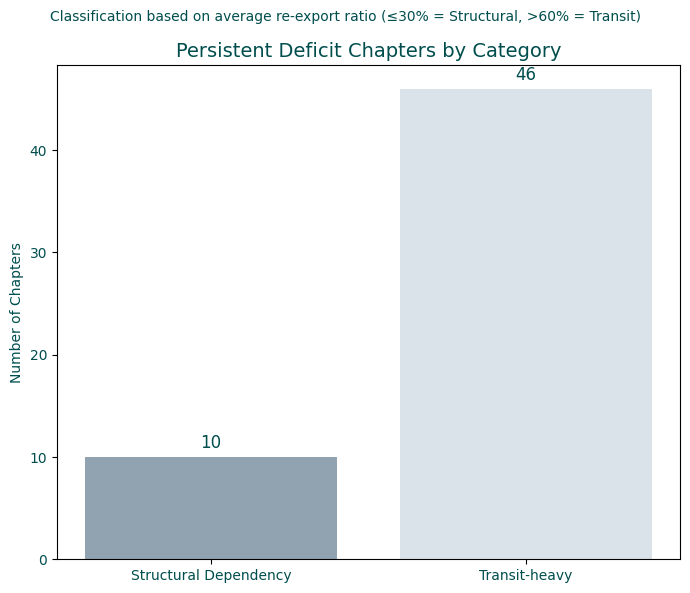

In [2]:
import matplotlib.pyplot as plt

# Filter only persistent deficit products
persistent = summary[summary['Flag_Persistent']]

# Count Structural vs Transit-heavy
counts = persistent['Category'].value_counts()[['Structural Dependency', 'Transit-heavy']]

# Custom colors
gray_azure   = '#91A3B0'  # Structural Dependency
grayish_blue = '#dbe3ea'  # Transit-heavy

# Column chart
plt.figure(figsize=(7,6))
bars = plt.bar(counts.index, counts.values, color=[gray_azure, grayish_blue])

# Add labels above bars
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.5,
             f"{int(bar.get_height())}",
             ha='center', va='bottom', fontsize=12, color='#004d4d')

# Styling
plt.title('Persistent Deficit Chapters by Category', fontsize=14, color='#004d4d')
plt.suptitle('Classification based on average re-export ratio (≤30% = Structural, >60% = Transit)',
             fontsize=10, color='#004d4d')

plt.ylabel('Number of Chapters', color='#004d4d')
plt.xticks(color='#004d4d')
plt.yticks(color='#004d4d')
plt.gca().set_facecolor('white')
plt.tight_layout()
plt.show()


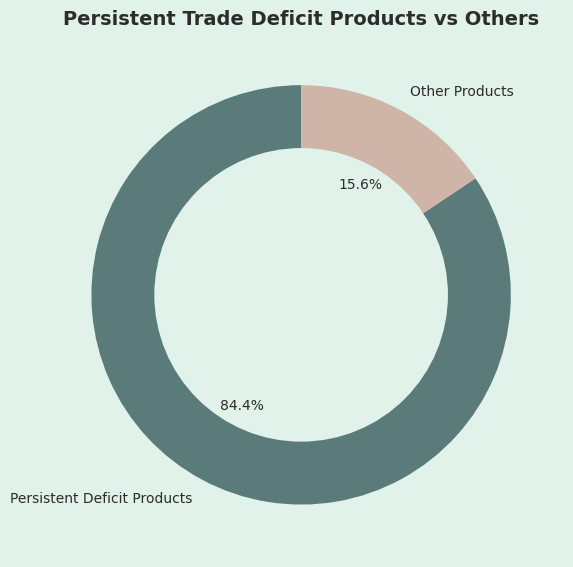

In [7]:
import matplotlib.pyplot as plt

# Persistent deficit defined as Deficit_Years >= 8
summary['Flag_Persistent'] = summary['Deficit_Years'] >= 8

# Count persistent vs non-persistent products
counts = summary['Flag_Persistent'].value_counts()
labels = ['Persistent Deficit Products','Other Products']

# Updated color theme (matching growth chart)
persistent_color = '#5B7B7A'   # muted teal for deficit
other_color      = '#CEB5A7'   # warm beige for others
background_color = '#E0F2E9'   # soft mint background
text_color       = '#2C2C2C'   # dark charcoal for strong contrast

# Donut chart
fig, ax = plt.subplots(figsize=(6,6), facecolor=background_color)
wedges, texts, autotexts = ax.pie(
    counts,
    labels=labels,
    autopct='%1.1f%%',
    colors=[persistent_color, other_color],
    startangle=90,
    wedgeprops=dict(width=0.4)
)

# Center circle for donut effect
centre_circle = plt.Circle((0,0),0.70,fc=background_color)
fig.gca().add_artist(centre_circle)

# Styling
plt.title('Persistent Trade Deficit Products vs Others', fontsize=14, fontweight='bold', color=text_color)
for t in texts + autotexts:
    t.set_color(text_color)

plt.tight_layout()
plt.show()


In [ ]:
# --- EXPORT IMBALANCE ANALYSIS FOR DASHBOARD ---
print("\n=== EXPORTING IMBALANCE ANALYSIS ===")

# Create export dataframe with key metrics
imbalance_export = summary[['ProductCode', 'ProductDescription', 'Deficit_Years',
                           'Mean_Net_Trade', 'Avg_Reexport_Ratio', 'Category']].copy()

# Add more detailed categorization
imbalance_export['Dependency_Type'] = imbalance_export['Category']
imbalance_export['Deficit_Severity'] = imbalance_export['Deficit_Years'].apply(
    lambda x: 'Critical' if x == 12 else ('High' if x >= 10 else ('Medium' if x >= 8 else 'Low'))
)

# Save to CSV
imbalance_export.to_csv('imbalance_analysis.csv', index=False)
print(f"✅ Imbalance analysis exported for {len(imbalance_export)} sectors")

# Show export preview
print("\n📊 Exported Data Preview:")
print(imbalance_export.head(10)[['ProductCode', 'ProductDescription', 'Deficit_Years', 'Dependency_Type']].to_string(index=False))

# Export summary statistics
print(f"\n📈 Summary Statistics:")
print(f"• Total sectors analyzed: {len(imbalance_export)}")
print(f"• Structural Dependency sectors: {len(imbalance_export[imbalance_export['Dependency_Type'] == 'Structural Dependency'])}")
print(f"• Transit-heavy sectors: {len(imbalance_export[imbalance_export['Dependency_Type'] == 'Transit-heavy'])}")
print(f"• Other sectors: {len(imbalance_export[imbalance_export['Dependency_Type'] == 'Other'])}")
print(f"• Sectors with 12-year deficits: {len(imbalance_export[imbalance_export['Deficit_Years'] == 12])}")


=== EXPORTING IMBALANCE ANALYSIS ===
✅ Imbalance analysis exported for 96 sectors

📊 Exported Data Preview:
 ProductCode                  ProductDescription  Deficit_Years       Dependency_Type
           1                        LIVE ANIMALS             11                 Other
           2          MEAT AND EDIBLE MEAT OFFAL             12         Transit-heavy
           3 FISH AND CRUSTACEANS, MOLLUSCS AND              12                 Other
           4 DAIRY PRODUCE; BIRDS' EGGS; NATURAL             12                 Other
           5 PRODUCTS OF ANIMAL ORIGIN, NOT ELSE             12         Transit-heavy
           6 LIVE TREES AND OTHER PLANTS; BULBS,             12 Structural Dependency
           7 EDIBLE VEGETABLES AND CERTAIN ROOTS             12         Transit-heavy
           8 EDIBLE FRUIT AND NUTS; PEEL OF CITR             12         Transit-heavy
           9        COFFEE, TEA, MATÉ AND SPICES             11         Transit-heavy
          10                   

In [ ]:
# --- DISPLAY TABLES ---
print("=== Top 5 Persistent Deficit Chapters by Deficit Size ===")

# Get actual top 5 by deficit magnitude
top5_deficit = summary.sort_values('Mean_Net_Trade', ascending=True).head(5)

print(top5_deficit[['ProductCode','ProductDescription','Deficit_Years','Mean_Net_Trade','Avg_Reexport_Ratio']]
      .to_string(index=False))

# Also show with better formatting
print("\n📊 Formatted for Report:")
for _, row in top5_deficit.iterrows():
    deficit_millions = abs(row['Mean_Net_Trade']) / 1_000
    print(f"HS-{row['ProductCode']:02d}: {row['ProductDescription']} | "
          f"Deficit: ${deficit_millions:,.0f}M")

=== Top 5 Persistent Deficit Chapters by Deficit Size ===
 ProductCode                  ProductDescription  Deficit_Years  Mean_Net_Trade  Avg_Reexport_Ratio
          84 NUCLEAR REACTORS, BOILERS, MACHINER             12   -1.230085e+07           91.136736
          71 NATURAL OR CULTURED PEARLS, PRECIOU             12   -1.172576e+07           50.202387
          85 ELECTRICAL MACHINERY AND EQUIPMENT              12   -1.026696e+07           92.614384
          87 VEHICLES OTHER THAN RAILWAY OR TRAM             12   -9.002529e+06           97.164918
          88 AIRCRAFT, SPACECRAFT, AND PARTS THE             10   -3.919120e+06           87.945572

📊 Formatted for Report:
HS-84: NUCLEAR REACTORS, BOILERS, MACHINER | Deficit: $12,301M
HS-71: NATURAL OR CULTURED PEARLS, PRECIOU | Deficit: $11,726M
HS-85: ELECTRICAL MACHINERY AND EQUIPMENT  | Deficit: $10,267M
HS-87: VEHICLES OTHER THAN RAILWAY OR TRAM | Deficit: $9,003M
HS-88: AIRCRAFT, SPACECRAFT, AND PARTS THE | Deficit: $3,919M


In [22]:
# Table 1: Top 5 Transit-Heavy Chapters (by deficit size)
print("=== Top 5 Transit-Heavy Chapters (Largest Deficits) ===")
top5_transit = transit_df.sort_values('Mean_Net_Trade', ascending=True).head(5)
print(top5_transit[['ProductCode','ProductDescription','Deficit_Years','Mean_Net_Trade','Avg_Reexport_Ratio']].to_string(index=False))

# Table 2: Top 5 Structural Dependency Chapters (by deficit size)
print("\n=== Top 5 Structural Dependency Chapters (Largest Deficits) ===")
top5_structural = structural_df.sort_values('Mean_Net_Trade', ascending=True).head(5)
print(top5_structural[['ProductCode','ProductDescription','Deficit_Years','Mean_Net_Trade','Avg_Reexport_Ratio']].to_string(index=False))

# 📊 REPORT Version
print("\n📊 REPORT Version:")

print("\nTransit-Heavy Examples:")
for _, row in top5_transit.iterrows():
    deficit_millions = abs(row['Mean_Net_Trade']) / 1_000
    print(f"HS-{row['ProductCode']:02d}: {row['ProductDescription']} | "
          f"Deficit: ${deficit_millions:,.0f}M | Re-export: {row['Avg_Reexport_Ratio']:.1f}%")

print("\nStructural Dependency Examples:")
for _, row in top5_structural.iterrows():
    deficit_millions = abs(row['Mean_Net_Trade']) / 1_000
    print(f"HS-{row['ProductCode']:02d}: {row['ProductDescription']} | "
          f"Deficit: ${deficit_millions:,.0f}M | Re-export: {row['Avg_Reexport_Ratio']:.1f}%")


=== Top 5 Transit-Heavy Chapters (Largest Deficits) ===
 ProductCode                  ProductDescription  Deficit_Years  Mean_Net_Trade  Avg_Reexport_Ratio
          84 NUCLEAR REACTORS, BOILERS, MACHINER             12   -1.230085e+07           91.136736
          85 ELECTRICAL MACHINERY AND EQUIPMENT              12   -1.026696e+07           92.614384
          87 VEHICLES OTHER THAN RAILWAY OR TRAM             12   -9.002529e+06           97.164918
          88 AIRCRAFT, SPACECRAFT, AND PARTS THE             10   -3.919120e+06           87.945572
          90 OPTICAL, PHOTOGRAPHIC, CINEMATOGRAP             12   -1.693290e+06           94.590956

=== Top 5 Structural Dependency Chapters (Largest Deficits) ===
 ProductCode                  ProductDescription  Deficit_Years  Mean_Net_Trade  Avg_Reexport_Ratio
          72                      IRON AND STEEL             12   -2.214604e+06           20.206205
          74         COPPER AND ARTICLES THEREOF             10   -7.081457e+05

In [ ]:
print("\nStructural Dependency Examples (Sorted by Deficit Size):")
top_structural_sorted = structural_df.sort_values('Mean_Net_Trade', ascending=True).head(5)
for _, row in top_structural_sorted.iterrows():
    deficit_millions = abs(row['Mean_Net_Trade']) / 1_000
    print(f"HS-{row['ProductCode']:02d}: {row['ProductDescription']} | "
          f"Deficit: ${deficit_millions:,.0f}M | Re-export: {row['Avg_Reexport_Ratio']:.1f}%")


Structural Dependency Examples (Sorted by Deficit Size):
HS-72: IRON AND STEEL | Deficit: $2,215M | Re-export: 20.2%
HS-74: COPPER AND ARTICLES THEREOF | Deficit: $708M | Re-export: 10.9%
HS-19: PREPARATIONS OF CEREALS, FLOUR, STA | Deficit: $463M | Re-export: 27.5%
HS-20: PREPARATIONS OF VEGETABLES, FRUIT,  | Deficit: $190M | Re-export: 24.3%
HS-47: PULP OF WOOD OR OF OTHER FIBROUS CE | Deficit: $127M | Re-export: 23.5%
